In [ ]:
from google.colab import drive
drive.mount("/content/drive")

DRIVE = "/content/drive/MyDrive/Corpus-tesis"
LOCAL = "/content/corpus"

!mkdir -p {LOCAL}
!unzip -q "{DRIVE}/corpus_real.zip" -d {LOCAL}
!ls {LOCAL}/real | wc -l

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
replace /content/corpus/real/guatemala_0000_Jimmy_Morales-Embajada.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: 500


In [ ]:
!pip install -q diffusers transformers accelerate safetensors scikit-image

In [ ]:
import torch, json, re, os, csv, unicodedata, traceback, time
import numpy as np
from PIL import Image, ImageFilter
from google.colab import drive

if not getattr(torch.Tensor.prod, "_parcheado", False):
    _prod_original = torch.Tensor.prod
    def _prod_sin_jit(self, *a, **k):
        if self.is_cuda and not self.is_floating_point():
            return _prod_original(self.cpu(), *a, **k).to(self.device)
        return _prod_original(self, *a, **k)
    _prod_sin_jit._parcheado = True
    torch.Tensor.prod = _prod_sin_jit

drive.mount("/content/drive")
DRIVE = "/content/drive/MyDrive/Corpus-tesis"
LOCAL = "/content/corpus"

for sub in ("manipuladas", "mascaras", "registros"):
    os.makedirs(f"{DRIVE}/{sub}", exist_ok=True)

if not os.path.isdir(f"{LOCAL}/real"):
    os.makedirs(LOCAL, exist_ok=True)
    !unzip -q "{DRIVE}/corpus_real.zip" -d {LOCAL}

REALES = sorted(os.listdir(f"{LOCAL}/real"))
print("imágenes reales:", len(REALES))

# calidad JPEG de cada real, para que la manipulada se guarde igual
CALIDAD = {}
with open(f"{LOCAL}/metadata_real.csv", encoding="utf-8") as f:
    for fila in csv.DictReader(f):
        CALIDAD[os.path.basename(fila["archivo"])] = int(fila["calidad_jpeg"])
print("calidades cargadas:", len(CALIDAD))

SEMILLA = 22500
META_NIVELES = {"obvio": 150, "normal": 175, "sutil": 175}
BANDAS = {"persona": {"obvio": (40, 100), "normal": (8, 40), "sutil": (0.5, 8)},
          "escena":  {"obvio": (3, 100),  "normal": (0.8, 3), "sutil": (0.1, 0.8)}}
RANGO_CAMBIO = {"obvio": (3, 20), "normal": (0.4, 2), "sutil": (0.05, 0.4)}

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
imágenes reales: 500
calidades cargadas: 500


In [ ]:
from transformers import (Qwen2_5_VLForConditionalGeneration, AutoProcessor,
                          Owlv2Processor, Owlv2ForObjectDetection,
                          SamModel, SamProcessor)
from diffusers import AutoPipelineForInpainting
from skimage.color import rgb2lab, deltaE_ciede2000

t0 = time.time()
vl      = Qwen2_5_VLForConditionalGeneration.from_pretrained(
              "Qwen/Qwen2.5-VL-7B-Instruct", dtype=torch.bfloat16, device_map="cuda")
vl_proc = AutoProcessor.from_pretrained("Qwen/Qwen2.5-VL-7B-Instruct")
od      = Owlv2ForObjectDetection.from_pretrained("google/owlv2-base-patch16-ensemble").to("cuda")
od_proc = Owlv2Processor.from_pretrained("google/owlv2-base-patch16-ensemble")
sam      = SamModel.from_pretrained("facebook/sam-vit-base").to("cuda")
sam_proc = SamProcessor.from_pretrained("facebook/sam-vit-base")
pipe = AutoPipelineForInpainting.from_pretrained(
    "diffusers/stable-diffusion-xl-1.0-inpainting-0.1", torch_dtype=torch.float16).to("cuda")

print(f"modelos cargados en {time.time()-t0:.0f} s — "
      f"GPU en uso: {torch.cuda.memory_allocated()/2**30:.1f} GB")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/418 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

The config attributes {'decay': 0.9999, 'inv_gamma': 1.0, 'min_decay': 0.0, 'optimization_step': 37000, 'power': 0.6666666666666666, 'update_after_step': 0, 'use_ema_warmup': False} were passed to UNet2DConditionModel, but are not expected and will be ignored. Please verify your config.json configuration file.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

modelos cargados en 28 s — GPU en uso: 22.9 GB


In [ ]:
INSTRUCCION = """Analiza esta fotografía política y propón TRES manipulaciones locales
creíbles como desinformación, sobre objetos de TAMAÑOS CLARAMENTE DISTINTOS.

Responde SOLO con un objeto JSON:
{"escena": "...", "ediciones": [{"tamano": "grande"|"mediano"|"pequeno",
  "objeto": "ENGLISH noun phrase", "cambio": "ENGLISH noun phrase",
  "evitar": "ENGLISH", "justificacion": "español"}]}

REGLAS:
1. "objeto", "cambio" y "evitar" EN INGLÉS.
2. "cambio" es SINTAGMA NOMINAL del objeto ya editado ("a blue silk necktie"),
   nunca una acción ("replace the tie", "ser cambiada por...").
3. PROHIBIDO editar caras, cabezas, pelo o manos.
4. NUNCA negaciones en "cambio": ni "instead of", ni "not", ni "without".
5. "objeto" debe ser específico: un detector lo buscará por esa frase.
6. Los tres tamaños distintos: grande (elemento dominante), mediano, pequeno (detalle).
NO clasifiques por dificultad. Solo por tamaño físico."""

NEGACIONES = ["instead of", " not ", "without", " no "]
VERBOS = ["ser ", "be ", "change", "replace", "make it", "turn into", "convert"]
ESPANOL = ["ser", "una", "por", "cambiada", "reemplazado", "corbata", "cuadro", "que"]
PROHIBIDOS_OBJ = ["face", "head", "hair", "hand", "cara", "rostro", "mano"]
TAMANOS = {"grande": "grande", "large": "grande", "big": "grande",
           "mediano": "mediano", "medium": "mediano",
           "pequeno": "pequeno", "pequena": "pequeno", "small": "pequeno"}

def normaliza(t):
    t = unicodedata.normalize("NFKD", str(t).lower().strip())
    return "".join(c for c in t if not unicodedata.combining(c))

def valida(e):
    t = normaliza(e.get("tamano", ""))
    assert t in TAMANOS, f"tamaño no reconocido: {e.get('tamano')!r}"
    e["tamano"] = TAMANOS[t]
    for campo in ("objeto", "cambio"):
        v = e[campo].lower()
        assert v.isascii(), f"'{campo}' no está en inglés: {e[campo]}"
        assert not any(f" {p} " in f" {v} " for p in ESPANOL), f"'{campo}' parece español"
    c = e["cambio"].lower()
    assert not any(n in f" {c} " for n in NEGACIONES), "negación en 'cambio'"
    assert not any(c.startswith(v) for v in VERBOS), "'cambio' no es sintagma nominal"
    assert not any(p in e["objeto"].lower() for p in PROHIBIDOS_OBJ), "objeto prohibido"
    ev = e.get("evitar", "")
    if (not ev) or (not ev.isascii()):
        e["evitar"] = f'the original {e["objeto"]}'

def proponer(img, intentos=4):
    msgs = [{"role": "user", "content": [{"type": "image", "image": img},
                                         {"type": "text", "text": INSTRUCCION}]}]
    texto = vl_proc.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    for i in range(intentos):
        inp = vl_proc(text=[texto], images=[img], return_tensors="pt").to("cuda")
        out = vl.generate(**inp, max_new_tokens=900, do_sample=(i > 0), temperature=0.8)
        crudo = vl_proc.batch_decode(out[:, inp.input_ids.shape[1]:], skip_special_tokens=True)[0]
        try:
            m = re.search(r"\{.*\}", crudo, re.S); assert m, "sin JSON"
            datos = json.loads(m.group(0))
            eds = datos["ediciones"][:3]
            assert len(eds) == 3, f"{len(eds)} ediciones"
            for e in eds: valida(e)
            return eds
        except Exception:
            continue
    raise RuntimeError("Qwen no cumplió el esquema")

def detectar(img, frases, umbral=0.15):
    inp = od_proc(text=[frases], images=img, return_tensors="pt").to("cuda")
    with torch.no_grad(): out = od(**inp)
    tam = torch.tensor([[img.size[1], img.size[0]]])
    try:
        r = od_proc.post_process_grounded_object_detection(out, threshold=umbral, target_sizes=tam)[0]
    except AttributeError:
        r = od_proc.post_process_object_detection(out, threshold=umbral, target_sizes=tam)[0]
    return [(r["scores"][i].item(), [int(v) for v in r["boxes"][i].tolist()])
            for i in range(len(r["scores"]))]

def segmentar(img, caja):
    inp = sam_proc(img, input_boxes=[[caja]], return_tensors="pt").to("cuda")
    with torch.no_grad(): out = sam(**inp)
    m = sam_proc.image_processor.post_process_masks(
        out.pred_masks.cpu(), inp["original_sizes"].cpu(), inp["reshaped_input_sizes"].cpu())
    return m[0][0, out.iou_scores[0, 0].argmax().item()].numpy()

def solapan(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    return ix*iy > 0.3 * min((a[2]-a[0])*(a[3]-a[1]), (b[2]-b[0])*(b[3]-b[1]))

def clasificar(area_rel, ref):
    for nivel, (lo, hi) in BANDAS[ref].items():
        if lo <= area_rel <= hi: return nivel
    return None

def localizar(img, e, prohibido, personas):
    W, H = img.size
    det = detectar(img, [e["objeto"]], 0.1)
    if not det: return None, "OWLv2 no encontró el objeto"
    det.sort(key=lambda d: -d[0])
    grupo = [c for _, c in det if solapan(det[0][1], c)]
    x0 = min(c[0] for c in grupo); y0 = min(c[1] for c in grupo)
    x1 = max(c[2] for c in grupo); y1 = max(c[3] for c in grupo)
    mx, my = int((x1-x0)*0.1), int((y1-y0)*0.1)
    caja = [max(0,x0-mx), max(0,y0-my), min(W,x1+mx), min(H,y1+my)]

    dil = np.asarray(Image.fromarray((segmentar(img, caja)*255).astype(np.uint8))
                     .filter(ImageFilter.MaxFilter(21))) > 0
    if (dil & prohibido).sum() / max(1, dil.sum()) > 0.10:
        return None, "la máscara toca cara o mano"
    mascara = dil & ~prohibido
    if mascara.sum() < 200: return None, "máscara demasiado pequeña"

    ys, xs = np.where(mascara); cx, cy = xs.mean(), ys.mean()
    dentro = [p for p in personas if p[0] <= cx <= p[2] and p[1] <= cy <= p[3]]
    if dentro:
        p = min(dentro, key=lambda b: (b[2]-b[0])*(b[3]-b[1]))
        ref_area, ref = (p[2]-p[0])*(p[3]-p[1]), "persona"
    else:
        ref_area, ref = W*H, "escena"

    area_rel = mascara.sum()/ref_area*100
    nivel = clasificar(area_rel, ref)
    if nivel is None: return None, f"área relativa {area_rel:.2f}% fuera de bandas"
    return dict(mascara=mascara, caja=caja, ref=ref, nivel=nivel,
                area_img=mascara.sum()/(W*H)*100, area_rel=area_rel), None

def generar(img, cand, e):
    W, H = img.size
    pequeno = cand["area_img"] < 1.0
    mask_pil = Image.fromarray((cand["mascara"]*255).astype(np.uint8))
    suave = mask_pil.filter(ImageFilter.GaussianBlur(3))
    salida = pipe(
        prompt=f'{e["cambio"]}, photorealistic photograph, natural indoor lighting',
        negative_prompt=f'{e["evitar"]}, cartoon, distorted, blurry, extra limbs, extra fingers',
        image=img, mask_image=mask_pil, width=W, height=H,
        num_inference_steps=40, guidance_scale=13.0 if pequeno else 11.0,
        strength=0.99, padding_mask_crop=64 if pequeno else 32,
        generator=torch.Generator("cuda").manual_seed(SEMILLA)).images[0]
    return pipe.image_processor.apply_overlay(suave, img, salida).convert("RGB"), mask_pil

def guardar_atomico(ruta, guardar_fn):
    tmp = ruta + ".tmp"
    guardar_fn(tmp)
    os.replace(tmp, ruta)

In [ ]:
hechas = {f[:-5] for f in os.listdir(f"{DRIVE}/registros") if f.endswith(".json")}
conteo = {"obvio": 0, "normal": 0, "sutil": 0}
for f in hechas:
    try:
        conteo[json.load(open(f"{DRIVE}/registros/{f}.json"))["nivel"]] += 1
    except Exception:
        pass
print(f"procesadas: {len(hechas)} — pendientes: {len(REALES)-len(hechas)} — niveles: {conteo}")

t_inicio = time.time()
for i, archivo in enumerate(REALES, 1):
    base = os.path.splitext(archivo)[0]
    if base in hechas:
        continue
    try:
        img = Image.open(f"{LOCAL}/real/{archivo}").convert("RGB")
        W, H = img.size
        lab_real = rgb2lab(np.asarray(img)); real_np = np.asarray(img)

        prohibido = np.zeros((H, W), bool)
        for _, (x0, y0, x1, y1) in detectar(img, ["a human face", "a human hand"], 0.1):
            mx, my = (x1-x0)//3, (y1-y0)//3
            prohibido[max(0,y0-my):min(H,y1+my), max(0,x0-mx):min(W,x1+mx)] = True
        personas = [c for _, c in detectar(img, ["a person"], 0.2)]

        ediciones = proponer(img)
        candidatos, motivos = [], []
        for e in ediciones:
            cand, motivo = localizar(img, e, prohibido, personas)
            if cand: candidatos.append((cand, e))
            else: motivos.append(f'{e["objeto"]}: {motivo}')
        assert candidatos, "ningún candidato válido — " + "; ".join(motivos)

        # prioriza el nivel que más falta para llegar a la meta
        def falta(c): return META_NIVELES[c[0]["nivel"]] - conteo[c[0]["nivel"]]
        candidatos.sort(key=falta, reverse=True)

        elegido = None
        for cand, e in candidatos[:2]:                      # máximo 2 generaciones
            compuesta, mask_pil = generar(img, cand, e)
            comp_np = np.asarray(compuesta)
            cambio = (deltaE_ciede2000(lab_real, rgb2lab(comp_np)) > 10).mean()*100
            lo, hi = RANGO_CAMBIO[cand["nivel"]]
            if lo <= cambio <= hi:
                elegido = (cand, e, compuesta, mask_pil, cambio); break
            motivos.append(f'{e["objeto"]}: cambio visible {cambio:.2f}% fuera de banda')
        assert elegido, "ninguna generación quedó en banda — " + "; ".join(motivos)

        cand, e, compuesta, mask_pil, cambio = elegido
        q = CALIDAD.get(archivo, 92)
        marca = (f'IMAGEN MANIPULADA CON IA - uso academico - modelo sdxl-1.0-inpainting-0.1 '
                 f'- semilla {SEMILLA} - prompt: {e["cambio"]}').encode()

        guardar_atomico(f"{DRIVE}/manipuladas/{archivo}",
                        lambda p: compuesta.save(p, "JPEG", quality=q, comment=marca))
        guardar_atomico(f"{DRIVE}/mascaras/{base}.png",
                        lambda p: mask_pil.save(p, "PNG"))

        registro = dict(archivo=archivo, nivel=cand["nivel"], tamano=e["tamano"],
                        objeto=e["objeto"], cambio=e["cambio"], evitar=e["evitar"],
                        caja=cand["caja"], ref=cand["ref"],
                        area_img=round(cand["area_img"], 3), area_rel=round(cand["area_rel"], 3),
                        cambio_visible=round(cambio, 3), calidad_jpeg=q, semilla=SEMILLA,
                        modelo_edicion="sdxl-1.0-inpainting-0.1", modelo_vlm="Qwen2.5-VL-7B-Instruct",
                        justificacion=e.get("justificacion", ""))
        guardar_atomico(f"{DRIVE}/registros/{base}.json",
                        lambda p: json.dump(registro, open(p, "w", encoding="utf-8"),
                                            indent=2, ensure_ascii=False))

        conteo[cand["nivel"]] += 1; hechas.add(base)
        transcurrido = time.time() - t_inicio
        print(f'[{i}/{len(REALES)}] {base[:40]:40s} → {cand["nivel"]:6s} '
              f'({e["objeto"][:20]}) área rel {cand["area_rel"]:5.1f}% '
              f'cambio {cambio:5.2f}% | {conteo} | {transcurrido/60:.0f} min')

    except Exception as err:
        with open(f"{DRIVE}/descartadas.csv", "a", encoding="utf-8") as f:
            f.write(f'{archivo},"{type(err).__name__}: {str(err)[:200]}"\n')
        print(f"[{i}/{len(REALES)}] {base[:40]} FALLÓ: {str(err)[:120]}")

print("\nlote terminado:", conteo, f"— {(time.time()-t_inicio)/60:.0f} min")

procesadas: 476 — pendientes: 24 — niveles: {'obvio': 147, 'normal': 165, 'sutil': 164}
[16/500] guatemala_0021_Dr._Alejandro_Giammattei_ FALLÓ: ningún candidato válido — blue sky: OWLv2 no encontró el objeto; white shirt collar: la máscara toca cara o mano; blue s


  0%|          | 0/39 [00:00<?, ?it/s]

  0%|          | 0/39 [00:00<?, ?it/s]

[77/500] guatemala_0159_Encapuchados_-_Huelga_de_ FALLÓ: ninguna generación quedó en banda — a group of people in the background: la máscara toca cara o mano; a large banner: ca


  0%|          | 0/39 [00:00<?, ?it/s]

[132/500] guatemala_0236_History_of_the_discovery_ FALLÓ: ninguna generación quedó en banda — crucifixion scene: área relativa 160.39% fuera de bandas; small religious icon on th
[163/500] guatemala_0276_Alvaro_Colom_Caballeros_c FALLÓ: ningún candidato válido — the flag on the left side of the image: la máscara toca cara o mano; the soldier's rifle: la m
[175/500] guatemala_0290_Attorney_General_Thelma_A FALLÓ: ningún candidato válido — background wall: OWLv2 no encontró el objeto; the man's suit jacket: la máscara toca cara o ma
[191/500] guatemala_0312_01.12_Jimmy_Morales_32109 FALLÓ: ningún candidato válido — the box of vitamin C: la máscara toca cara o mano; the box of vitamin C: la máscara toca cara 


... (8 outputs left out)

[394/500] norteamerica_0255_Donald_Trump_rally_in_ FALLÓ: ninguna generación quedó en banda — a red silk necktie: cambio visible 1.23% fuera de banda; a sign held by a supporter:


  0%|          | 0/39 [00:00<?, ?it/s]

  0%|          | 0/39 [00:00<?, ?it/s]

[400/500] norteamerica_0263_Barack_Obama_Californi FALLÓ: ninguna generación quedó en banda — microphone: cambio visible 0.41% fuera de banda; suit jacket: cambio visible 3.22% f
[456/500] norteamerica_0326_Senate_hearing_130604- FALLÓ: ningún candidato válido — microphone: la máscara toca cara o mano; water bottle: la máscara toca cara o mano; watch on t

lote terminado: {'obvio': 147, 'normal': 165, 'sutil': 164} — 8 min


In [ ]:
SEMILLA = 22501
print("semilla para esta pasada:", SEMILLA)

semilla para esta pasada: 22501


In [ ]:
INSTRUCCION_ORIGINAL = INSTRUCCION

INSTRUCCION_PERSONA = """Analiza esta fotografía política y propón TRES manipulaciones locales
creíbles como desinformación, sobre OBJETOS QUE LLEVAN PUESTOS O SOSTIENEN LAS PERSONAS.

Responde SOLO con un objeto JSON:
{"escena": "...", "ediciones": [{"tamano": "grande"|"mediano"|"pequeno",
  "objeto": "ENGLISH noun phrase", "cambio": "ENGLISH noun phrase",
  "evitar": "ENGLISH", "justificacion": "español"}]}

REGLAS:
1. "objeto", "cambio" y "evitar" EN INGLÉS.
2. "cambio" es SINTAGMA NOMINAL del objeto ya editado, nunca una acción.
3. PROHIBIDO editar caras, cabezas, pelo o manos.
4. PROHIBIDO editar objetos del entorno: cuadros, muebles, plantas, paredes, ventanas.
5. El objeto DEBE ser algo que una persona lleva puesto o sostiene:
   saco, traje, camisa, corbata, broche, insignia, reloj, carpeta, documento, micrófono.
6. NUNCA negaciones en "cambio".
7. Los tres tamaños distintos: grande (una prenda completa), mediano (una prenda
   secundaria o un objeto sostenido), pequeno (un accesorio o detalle).
NO clasifiques por dificultad. Solo por tamaño físico."""

INSTRUCCION = INSTRUCCION_PERSONA          # proponer() lee esta global

hechas = {f[:-5] for f in os.listdir(f"{DRIVE}/registros") if f.endswith(".json")}
conteo = {"obvio": 0, "normal": 0, "sutil": 0}
for f in hechas:
    try: conteo[json.load(open(f"{DRIVE}/registros/{f}.json"))["nivel"]] += 1
    except Exception: pass
print(f"pasada de rescate — ya hechas: {len(hechas)}, pendientes: {len(REALES)-len(hechas)}")

rescatadas = 0
t_inicio = time.time()
try:
    for i, archivo in enumerate(REALES, 1):
        base = os.path.splitext(archivo)[0]
        if base in hechas:
            continue
        try:
            img = Image.open(f"{LOCAL}/real/{archivo}").convert("RGB")
            W, H = img.size
            lab_real = rgb2lab(np.asarray(img))

            # zona prohibida: margen amplio arriba y a los lados, mínimo hacia abajo,
            # para no tapar cuello, corbata ni solapas
            prohibido = np.zeros((H, W), bool)
            for _, (x0, y0, x1, y1) in detectar(img, ["a human face", "a human hand"], 0.1):
                mx, arriba, abajo = (x1-x0)//4, (y1-y0)//3, (y1-y0)//12
                prohibido[max(0,y0-arriba):min(H,y1+abajo), max(0,x0-mx):min(W,x1+mx)] = True

            personas = [c for _, c in detectar(
                img, ["a person", "a man in a suit", "a woman", "a person standing"], 0.08)]
            assert personas, "no se detectaron personas"

            ediciones = proponer(img)
            candidatos, motivos = [], []
            for e in ediciones:
                cand, motivo = localizar(img, e, prohibido, personas)
                if cand is None:
                    motivos.append(f'{e["objeto"]}: {motivo}'); continue
                if cand["ref"] != "persona":
                    motivos.append(f'{e["objeto"]}: cayó en el entorno'); continue
                candidatos.append((cand, e))
            assert candidatos, "sin candidatos sobre personas — " + "; ".join(motivos)

            def falta(c): return META_NIVELES[c[0]["nivel"]] - conteo[c[0]["nivel"]]
            candidatos.sort(key=falta, reverse=True)

            elegido = None
            for cand, e in candidatos[:2]:
                compuesta, mask_pil = generar(img, cand, e)
                cambio = (deltaE_ciede2000(lab_real, rgb2lab(np.asarray(compuesta))) > 10).mean()*100
                lo, hi = RANGO_CAMBIO[cand["nivel"]]
                if lo <= cambio <= hi:
                    elegido = (cand, e, compuesta, mask_pil, cambio); break
                motivos.append(f'{e["objeto"]}: cambio {cambio:.2f}% fuera de banda')
            assert elegido, "ninguna generación en banda — " + "; ".join(motivos)

            cand, e, compuesta, mask_pil, cambio = elegido
            q = CALIDAD.get(archivo, 92)
            marca = (f'IMAGEN MANIPULADA CON IA - uso academico - modelo sdxl-1.0-inpainting-0.1 '
                     f'- semilla {SEMILLA} - prompt: {e["cambio"]}').encode()

            guardar_atomico(f"{DRIVE}/manipuladas/{archivo}",
                            lambda p: compuesta.save(p, "JPEG", quality=q, comment=marca))
            guardar_atomico(f"{DRIVE}/mascaras/{base}.png", lambda p: mask_pil.save(p, "PNG"))

            registro = dict(archivo=archivo, nivel=cand["nivel"], tamano=e["tamano"],
                            objeto=e["objeto"], cambio=e["cambio"], evitar=e["evitar"],
                            caja=cand["caja"], ref=cand["ref"], pasada="persona",
                            personas_detectadas=len(personas),
                            area_img=round(cand["area_img"], 3), area_rel=round(cand["area_rel"], 3),
                            cambio_visible=round(cambio, 3), calidad_jpeg=q, semilla=SEMILLA,
                            modelo_edicion="sdxl-1.0-inpainting-0.1",
                            modelo_vlm="Qwen2.5-VL-7B-Instruct",
                            justificacion=e.get("justificacion", ""))
            guardar_atomico(f"{DRIVE}/registros/{base}.json",
                            lambda p: json.dump(registro, open(p, "w", encoding="utf-8"),
                                                indent=2, ensure_ascii=False))

            conteo[cand["nivel"]] += 1; hechas.add(base); rescatadas += 1
            print(f'[{i}/{len(REALES)}] {base[:38]:38s} → {cand["nivel"]:6s} '
                  f'({e["objeto"][:22]}) rel {cand["area_rel"]:5.1f}% cambio {cambio:5.2f}% '
                  f'| rescatadas {rescatadas} | {conteo}')
        except Exception as err:
            with open(f"{DRIVE}/descartadas.csv", "a", encoding="utf-8") as f:
                f.write(f'{archivo},"persona: {type(err).__name__}: {str(err)[:180]}"\n')
finally:
    INSTRUCCION = INSTRUCCION_ORIGINAL

print(f"\nrescatadas en esta pasada: {rescatadas} — {(time.time()-t_inicio)/60:.0f} min")

pasada de rescate — ya hechas: 476, pendientes: 24


  0%|          | 0/39 [00:00<?, ?it/s]

  0%|          | 0/39 [00:00<?, ?it/s]

  0%|          | 0/39 [00:00<?, ?it/s]

  0%|          | 0/39 [00:00<?, ?it/s]

  0%|          | 0/39 [00:00<?, ?it/s]

  0%|          | 0/39 [00:00<?, ?it/s]

  0%|          | 0/39 [00:00<?, ?it/s]

  0%|          | 0/39 [00:00<?, ?it/s]


rescatadas en esta pasada: 0 — 7 min


In [ ]:
SEMILLA = 22500
print("semilla restaurada:", SEMILLA)

semilla restaurada: 22500


In [ ]:
BANDAS_R = {"persona": {"obvio": (40, 100), "normal": (8, 40), "sutil": (0.04, 8)},
            "escena":  {"obvio": (3, 100),  "normal": (0.8, 3), "sutil": (0.008, 0.8)}}

RANGO_CAMBIO_R = dict(RANGO_CAMBIO, sutil=(0.02, 0.4))

def localizar_relajado(img, e, prohibido, personas):
    W, H = img.size
    det = detectar(img, [e["objeto"]], 0.05)
    if not det:                                   # reintento con el núcleo del sintagma
        corto = " ".join(e["objeto"].replace(",", " ").split()[-2:])
        det = detectar(img, [corto], 0.05)
    if not det: return None, "OWLv2 no encontró"

    det.sort(key=lambda d: -d[0])
    grupo = [c for _, c in det if solapan(det[0][1], c)]
    x0 = min(c[0] for c in grupo); y0 = min(c[1] for c in grupo)
    x1 = max(c[2] for c in grupo); y1 = max(c[3] for c in grupo)
    mx, my = int((x1-x0)*0.1), int((y1-y0)*0.1)
    caja = [max(0,x0-mx), max(0,y0-my), min(W,x1+mx), min(H,y1+my)]

    dil = np.asarray(Image.fromarray((segmentar(img, caja)*255).astype(np.uint8))
                     .filter(ImageFilter.MaxFilter(21))) > 0
    mascara = dil & ~prohibido                    # recorta en vez de rechazar
    if mascara.sum() < 0.60 * dil.sum():
        return None, "la cara o mano se come el objeto"
    if mascara.sum() < 200: return None, "máscara demasiado pequeña"

    ys, xs = np.where(mascara); cx, cy = xs.mean(), ys.mean()
    dentro = [p for p in personas if p[0] <= cx <= p[2] and p[1] <= cy <= p[3]]
    if dentro:
        p = min(dentro, key=lambda b: (b[2]-b[0])*(b[3]-b[1]))
        ref_area, ref = (p[2]-p[0])*(p[3]-p[1]), "persona"
    else:
        ref_area, ref = W*H, "escena"

    area_rel = mascara.sum()/ref_area*100
    nivel = next((n for n, (lo, hi) in BANDAS_R[ref].items() if lo <= area_rel <= hi), None)
    if nivel is None: return None, f"área relativa {area_rel:.2f}% fuera de bandas"
    return dict(mascara=mascara, caja=caja, ref=ref, nivel=nivel,
                area_img=mascara.sum()/(W*H)*100, area_rel=area_rel), None


hechas = {f[:-5] for f in os.listdir(f"{DRIVE}/registros") if f.endswith(".json")}
conteo = {"obvio": 0, "normal": 0, "sutil": 0}
for f in hechas:
    try: conteo[json.load(open(f"{DRIVE}/registros/{f}.json"))["nivel"]] += 1
    except Exception: pass
print(f"pasada final — hechas: {len(hechas)}, pendientes: {len(REALES)-len(hechas)}")

cerradas, t0 = 0, time.time()
for i, archivo in enumerate(REALES, 1):
    base = os.path.splitext(archivo)[0]
    if base in hechas: continue
    try:
        img = Image.open(f"{LOCAL}/real/{archivo}").convert("RGB")
        W, H = img.size
        lab_real = rgb2lab(np.asarray(img))

        prohibido = np.zeros((H, W), bool)
        for _, (x0, y0, x1, y1) in detectar(img, ["a human face", "a human hand"], 0.1):
            mx, arriba, abajo = (x1-x0)//4, (y1-y0)//3, (y1-y0)//12
            prohibido[max(0,y0-arriba):min(H,y1+abajo), max(0,x0-mx):min(W,x1+mx)] = True
        personas = [c for _, c in detectar(
            img, ["a person", "a man in a suit", "a woman", "a person standing"], 0.08)]

        candidatos, motivos = [], []
        for e in proponer(img):
            cand, motivo = localizar_relajado(img, e, prohibido, personas)
            if cand: candidatos.append((cand, e))
            else: motivos.append(f'{e["objeto"]}: {motivo}')
        assert candidatos, "sin candidatos — " + "; ".join(motivos)

        candidatos.sort(key=lambda c: META_NIVELES[c[0]["nivel"]] - conteo[c[0]["nivel"]], reverse=True)

        elegido = None
        for cand, e in candidatos[:2]:
            compuesta, mask_pil = generar(img, cand, e)
            cambio = (deltaE_ciede2000(lab_real, rgb2lab(np.asarray(compuesta))) > 10).mean()*100
            lo, hi = RANGO_CAMBIO_R[cand["nivel"]]
            if lo <= cambio <= hi:
                elegido = (cand, e, compuesta, mask_pil, cambio); break
            motivos.append(f'{e["objeto"]}: cambio {cambio:.2f}% fuera de banda')
        assert elegido, "ninguna generación en banda — " + "; ".join(motivos)

        cand, e, compuesta, mask_pil, cambio = elegido
        q = CALIDAD.get(archivo, 92)
        marca = (f'IMAGEN MANIPULADA CON IA - uso academico - modelo sdxl-1.0-inpainting-0.1 '
                 f'- semilla {SEMILLA} - prompt: {e["cambio"]}').encode()
        guardar_atomico(f"{DRIVE}/manipuladas/{archivo}",
                        lambda p: compuesta.save(p, "JPEG", quality=q, comment=marca))
        guardar_atomico(f"{DRIVE}/mascaras/{base}.png", lambda p: mask_pil.save(p, "PNG"))

        registro = dict(archivo=archivo, nivel=cand["nivel"], tamano=e["tamano"],
                        objeto=e["objeto"], cambio=e["cambio"], evitar=e["evitar"],
                        caja=cand["caja"], ref=cand["ref"], pasada="final_relajada",
                        personas_detectadas=len(personas),
                        area_img=round(cand["area_img"], 3), area_rel=round(cand["area_rel"], 3),
                        cambio_visible=round(cambio, 3), calidad_jpeg=q, semilla=SEMILLA,
                        modelo_edicion="sdxl-1.0-inpainting-0.1",
                        modelo_vlm="Qwen2.5-VL-7B-Instruct",
                        justificacion=e.get("justificacion", ""))
        guardar_atomico(f"{DRIVE}/registros/{base}.json",
                        lambda p: json.dump(registro, open(p, "w", encoding="utf-8"),
                                            indent=2, ensure_ascii=False))

        conteo[cand["nivel"]] += 1; hechas.add(base); cerradas += 1
        print(f'[{i}] {base[:36]:36s} → {cand["nivel"]:6s} {cand["ref"]:7s} '
              f'({e["objeto"][:20]}) rel {cand["area_rel"]:5.1f}% | cerradas {cerradas} | {conteo}')
    except Exception as err:
        with open(f"{DRIVE}/descartadas.csv", "a", encoding="utf-8") as f:
            f.write(f'{archivo},"final: {type(err).__name__}: {str(err)[:180]}"\n')

print(f"\ncerradas en esta pasada: {cerradas} — {(time.time()-t0)/60:.0f} min")

pasada final — hechas: 476, pendientes: 24


  0%|          | 0/39 [00:00<?, ?it/s]

  0%|          | 0/39 [00:00<?, ?it/s]

  0%|          | 0/39 [00:00<?, ?it/s]

  0%|          | 0/39 [00:00<?, ?it/s]

  0%|          | 0/39 [00:00<?, ?it/s]

... (15 outputs left out)

  0%|          | 0/39 [00:00<?, ?it/s]

  0%|          | 0/39 [00:00<?, ?it/s]

  0%|          | 0/39 [00:00<?, ?it/s]


cerradas en esta pasada: 0 — 9 min


In [ ]:
import random
random.seed(SEMILLA)

INSERCIONES = [
    ("a framed photograph hanging on the wall",  "empty wall"),
    ("a national flag on a floor pole",          "empty floor"),
    ("a dark leather folder on the table",       "empty table"),
    ("a potted green plant",                     "empty corner"),
    ("a wooden lectern with a microphone",       "empty floor"),
]
INSERCIONES_PERSONA = [
    ("a man in a dark business suit standing, photorealistic",  "empty floor, cartoon, mannequin, doll"),
    ("a woman in a formal blazer standing, photorealistic",     "empty floor, cartoon, mannequin, doll"),
    ("a person in a military uniform standing, photorealistic", "empty floor, cartoon, mannequin, doll"),
]
OBJETIVO = {"obvio": 6.0, "normal": 1.6, "sutil": 0.45}   # % de la imagen

hechas = {f[:-5] for f in os.listdir(f"{DRIVE}/registros") if f.endswith(".json")}
conteo = {"obvio": 0, "normal": 0, "sutil": 0}
for f in hechas:
    try: conteo[json.load(open(f"{DRIVE}/registros/{f}.json"))["nivel"]] += 1
    except Exception: pass
print(f"inserción — hechas: {len(hechas)}, pendientes: {len(REALES)-len(hechas)}")

insertadas, t0 = 0, time.time()
for i, archivo in enumerate(REALES, 1):
    base = os.path.splitext(archivo)[0]
    if base in hechas: continue
    try:
        img = Image.open(f"{LOCAL}/real/{archivo}").convert("RGB")
        W, H = img.size
        lab_real = rgb2lab(np.asarray(img))

        ocupado = np.zeros((H, W), bool)
        for _, (x0,y0,x1,y1) in detectar(img, ["a human face","a human hand"], 0.1):
            mx, my = (x1-x0)//3, (y1-y0)//3
            ocupado[max(0,y0-my):min(H,y1+my), max(0,x0-mx):min(W,x1+mx)] = True
        for x0,y0,x1,y1 in [c for _, c in detectar(img, ["a person"], 0.1)]:
            ocupado[max(0,y0):min(H,y1), max(0,x0):min(W,x1)] = True

        nivel = min(conteo, key=lambda n: conteo[n] - META_NIVELES[n])
        es_persona = (nivel == "obvio")
        area_px = OBJETIVO[nivel]/100 * W * H
        if es_persona:                       # rectángulo vertical para una figura de pie
            ancho = max(24, int((area_px/2) ** 0.5)); alto = min(2*ancho, H)
        else:
            ancho = alto = max(24, int(area_px ** 0.5))
        ancho, alto = min(ancho, W//2), min(alto, H-2)

        region = None
        for _ in range(400):
            x = random.randint(0, W-ancho); y = random.randint(0, H-alto)
            if not ocupado[y:y+alto, x:x+ancho].any():
                region = (x, y, x+ancho, y+alto); break
        assert region, "no hay región libre suficiente"

        mascara = np.zeros((H, W), bool)
        mascara[region[1]:region[3], region[0]:region[2]] = True
        cand = dict(mascara=mascara, caja=list(region), ref="escena", nivel=nivel,
                    area_img=mascara.sum()/(W*H)*100, area_rel=mascara.sum()/(W*H)*100)

        opciones = INSERCIONES_PERSONA if es_persona else INSERCIONES
        elegido = None
        for cambio_txt, evitar_txt in random.sample(opciones, min(2, len(opciones))):
            e = {"cambio": cambio_txt, "evitar": evitar_txt, "objeto": cambio_txt,
                 "tamano": {"obvio":"grande","normal":"mediano","sutil":"pequeno"}[nivel],
                 "justificacion": ("inserción de una persona que no estaba en la escena"
                                   if es_persona else
                                   "inserción de objeto en región libre de la escena")}
            compuesta, mask_pil = generar(img, cand, e)
            cambio = (deltaE_ciede2000(lab_real, rgb2lab(np.asarray(compuesta))) > 10).mean()*100
            lo, hi = RANGO_CAMBIO[nivel]
            if lo <= cambio <= hi:
                elegido = (e, compuesta, mask_pil, cambio); break
        assert elegido, "ninguna inserción quedó en banda"

        e, compuesta, mask_pil, cambio = elegido
        q = CALIDAD.get(archivo, 92)
        marca = (f'IMAGEN MANIPULADA CON IA - uso academico - modelo sdxl-1.0-inpainting-0.1 '
                 f'- semilla {SEMILLA} - prompt: {e["cambio"]}').encode()
        guardar_atomico(f"{DRIVE}/manipuladas/{archivo}",
                        lambda p: compuesta.save(p, "JPEG", quality=q, comment=marca))
        guardar_atomico(f"{DRIVE}/mascaras/{base}.png", lambda p: mask_pil.save(p, "PNG"))

        registro = dict(archivo=archivo, nivel=nivel, tamano=e["tamano"],
                        objeto=e["objeto"], cambio=e["cambio"], evitar=e["evitar"],
                        caja=cand["caja"], ref="escena",
                        pasada="insercion_persona" if es_persona else "insercion_region_libre",
                        area_img=round(cand["area_img"],3), area_rel=round(cand["area_rel"],3),
                        cambio_visible=round(cambio,3), calidad_jpeg=q, semilla=SEMILLA,
                        modelo_edicion="sdxl-1.0-inpainting-0.1", modelo_vlm="ninguno",
                        justificacion=e["justificacion"])
        guardar_atomico(f"{DRIVE}/registros/{base}.json",
                        lambda p: json.dump(registro, open(p,"w",encoding="utf-8"),
                                            indent=2, ensure_ascii=False))
        conteo[nivel] += 1; hechas.add(base); insertadas += 1
        print(f'[{i}] {base[:34]:34s} → {nivel:6s} '
              f'{"persona" if es_persona else "objeto ":8s} {cand["area_img"]:5.2f}% '
              f'cambio {cambio:5.2f}% | insertadas {insertadas}')
    except Exception as err:
        with open(f"{DRIVE}/descartadas.csv","a",encoding="utf-8") as f:
            f.write(f'{archivo},"insercion: {type(err).__name__}: {str(err)[:150]}"\n')

print(f"\ninsertadas: {insertadas} — {(time.time()-t0)/60:.0f} min")

inserción — hechas: 476, pendientes: 24


  0%|          | 0/39 [00:00<?, ?it/s]

  0%|          | 0/39 [00:00<?, ?it/s]

  0%|          | 0/39 [00:00<?, ?it/s]

  0%|          | 0/39 [00:00<?, ?it/s]

  0%|          | 0/39 [00:00<?, ?it/s]

[204] guatemala_0325_Palacio_Nacional_02 → sutil  objeto    0.45% cambio  0.06% | insertadas 1


  0%|          | 0/39 [00:00<?, ?it/s]

  0%|          | 0/39 [00:00<?, ?it/s]


insertadas: 1 — 1 min


In [ ]:
import random

VOCAB = {
 "prenda":     ["necktie","bow tie","suit jacket","blazer","dress shirt","scarf","vest",
                "overcoat","shirt collar","trousers","shoes","belt"],
 "accesorio":  ["lapel pin","wristwatch","eyeglasses","ring","earring","necklace",
                "name badge","identification badge","bracelet"],
 "objeto":     ["leather folder","notebook","document","pen","microphone","bottle",
                "glass of water","cup","smartphone","briefcase","book","sheet of paper"],
 "mobiliario": ["wooden chair","armchair","table","desk","lamp","bookshelf","sofa",
                "podium","lectern","carpet","curtain","wooden door","window"],
 "decoracion": ["flag","flag pole","picture frame","painting on the wall",
                "photograph on the wall","potted plant","flower arrangement","vase",
                "wall clock","chandelier","sculpture","banner"],
}
CAMBIO_POR_CAT = {
 "prenda":     ["a bright red {}", "a dark green {}", "a white {}", "a navy blue {}"],
 "accesorio":  ["a silver {}", "a gold {}", "a black {}"],
 "objeto":     ["a red {}", "a black {}", "a bright yellow {}"],
 "mobiliario": ["a modern black {}", "a white painted {}", "a glass {}"],
 "decoracion": ["a plain dark blue {}", "a bright red {}", "a golden {}"],
}

VOCABULARIO = [t for lista in VOCAB.values() for t in lista]
CATEGORIA = {t: cat for cat, lista in VOCAB.items() for t in lista}

def cambio_de(frase):
    rnd = random.Random(f"{SEMILLA}{frase}")          # determinista y reproducible
    return rnd.choice(CAMBIO_POR_CAT[CATEGORIA[frase]]).format(frase)

hechas = {f[:-5] for f in os.listdir(f"{DRIVE}/registros") if f.endswith(".json")}
conteo = {"obvio": 0, "normal": 0, "sutil": 0}
for f in hechas:
    try: conteo[json.load(open(f"{DRIVE}/registros/{f}.json"))["nivel"]] += 1
    except Exception: pass
print(f"vocabulario fijo — pendientes: {len(REALES)-len(hechas)}")

cerradas, t0 = 0, time.time()
for i, archivo in enumerate(REALES, 1):
    base = os.path.splitext(archivo)[0]
    if base in hechas: continue
    try:
        img = Image.open(f"{LOCAL}/real/{archivo}").convert("RGB")
        W, H = img.size
        lab_real = rgb2lab(np.asarray(img))

        prohibido = np.zeros((H, W), bool)
        for _, (x0,y0,x1,y1) in detectar(img, ["a human face","a human hand"], 0.1):
            mx, arriba, abajo = (x1-x0)//4, (y1-y0)//3, (y1-y0)//12
            prohibido[max(0,y0-arriba):min(H,y1+abajo), max(0,x0-mx):min(W,x1+mx)] = True
        personas = [c for _, c in detectar(img, ["a person","a man in a suit","a woman"], 0.08)]

        hallados = []                      # qué hay realmente en la foto
        for frase in VOCABULARIO:
            det = detectar(img, [frase], 0.09)
            if det:
                sc, caja = max(det, key=lambda d: d[0])
                hallados.append((sc, frase, caja))
        assert hallados, "el vocabulario no encontró ningún objeto"
        hallados.sort(key=lambda h: -h[0])

        candidatos = []
        for sc, frase, caja in hallados[:20]:
            dil = np.asarray(Image.fromarray((segmentar(img, caja)*255).astype(np.uint8))
                             .filter(ImageFilter.MaxFilter(21))) > 0
            m = dil & ~prohibido
            if m.sum() < 0.6*dil.sum() or m.sum() < 200: continue
            ys, xs = np.where(m); cx, cy = xs.mean(), ys.mean()
            dentro = [p for p in personas if p[0] <= cx <= p[2] and p[1] <= cy <= p[3]]
            if dentro:
                p = min(dentro, key=lambda b: (b[2]-b[0])*(b[3]-b[1]))
                ref_area, ref = (p[2]-p[0])*(p[3]-p[1]), "persona"
            else:
                ref_area, ref = W*H, "escena"
            area_rel = m.sum()/ref_area*100
            nivel = next((n for n,(lo,hi) in BANDAS_R[ref].items() if lo <= area_rel <= hi), None)
            if nivel is None: continue
            candidatos.append((dict(mascara=m, caja=caja, ref=ref, nivel=nivel,
                                    area_img=m.sum()/(W*H)*100, area_rel=area_rel),
                               {"objeto": frase, "cambio": cambio_de(frase),
                                "evitar": f"the original {frase}",
                                "tamano": {"obvio":"grande","normal":"mediano","sutil":"pequeno"}[nivel],
                                "justificacion": "edición de objeto detectado por vocabulario fijo"}))
        assert candidatos, "ningún objeto del vocabulario quedó utilizable"
        candidatos.sort(key=lambda c: META_NIVELES[c[0]["nivel"]] - conteo[c[0]["nivel"]], reverse=True)

        elegido = None
        for cand, e in candidatos[:3]:
            compuesta, mask_pil = generar(img, cand, e)
            cambio = (deltaE_ciede2000(lab_real, rgb2lab(np.asarray(compuesta))) > 10).mean()*100
            lo, hi = RANGO_CAMBIO_R[cand["nivel"]]
            if lo <= cambio <= hi:
                elegido = (cand, e, compuesta, mask_pil, cambio); break
        assert elegido, "ninguna generación quedó en banda"

        cand, e, compuesta, mask_pil, cambio = elegido
        q = CALIDAD.get(archivo, 92)
        marca = (f'IMAGEN MANIPULADA CON IA - uso academico - modelo sdxl-1.0-inpainting-0.1 '
                 f'- semilla {SEMILLA} - prompt: {e["cambio"]}').encode()
        guardar_atomico(f"{DRIVE}/manipuladas/{archivo}",
                        lambda p: compuesta.save(p, "JPEG", quality=q, comment=marca))
        guardar_atomico(f"{DRIVE}/mascaras/{base}.png", lambda p: mask_pil.save(p, "PNG"))
        registro = dict(archivo=archivo, nivel=cand["nivel"], tamano=e["tamano"],
                        objeto=e["objeto"], cambio=e["cambio"], evitar=e["evitar"],
                        caja=cand["caja"], ref=cand["ref"], pasada="vocabulario_fijo",
                        area_img=round(cand["area_img"],3), area_rel=round(cand["area_rel"],3),
                        cambio_visible=round(cambio,3), calidad_jpeg=q, semilla=SEMILLA,
                        modelo_edicion="sdxl-1.0-inpainting-0.1", modelo_vlm="ninguno",
                        justificacion=e["justificacion"])
        guardar_atomico(f"{DRIVE}/registros/{base}.json",
                        lambda p: json.dump(registro, open(p,"w",encoding="utf-8"),
                                            indent=2, ensure_ascii=False))
        conteo[cand["nivel"]] += 1; hechas.add(base); cerradas += 1
        print(f'[{i}] {base[:34]:34s} → {cand["nivel"]:6s} {cand["ref"]:7s} '
              f'({e["objeto"][:18]}) rel {cand["area_rel"]:5.1f}% | cerradas {cerradas}')
    except Exception as err:
        with open(f"{DRIVE}/descartadas.csv","a",encoding="utf-8") as f:
            f.write(f'{archivo},"vocab: {type(err).__name__}: {str(err)[:150]}"\n')

print(f"\ncerradas: {cerradas} — {(time.time()-t0)/60:.0f} min")

vocabulario fijo — pendientes: 6


  0%|          | 0/39 [00:00<?, ?it/s]

  0%|          | 0/39 [00:00<?, ?it/s]

  0%|          | 0/39 [00:00<?, ?it/s]

  0%|          | 0/39 [00:00<?, ?it/s]

  0%|          | 0/39 [00:00<?, ?it/s]

  0%|          | 0/39 [00:00<?, ?it/s]

  0%|          | 0/39 [00:00<?, ?it/s]

  0%|          | 0/39 [00:00<?, ?it/s]


cerradas: 0 — 3 min


# Imágenes sin su par manipulado

['guatemala_0021_Dr._Alejandro_Giammattei_Falla.jpg', 'norteamerica_0063_Hillary_Clinton_Iowa_April_2015.jpg', 'norteamerica_0069_MSM_spotlights_Donald_Trump_vs._Hillary_Clinton_and_Bernie_Sanders_24311159914.jpg', 'norteamerica_0138_Andres_Manuel_Lopez_Obrador_en_2008.jpg', 'norteamerica_0177_Lenin_Moreno_con_el_lider_mexicano_Lopez_Obrador_cropped.jpg', 'norteamerica_0203_Justin_Trudeau_December_2015.jpg']


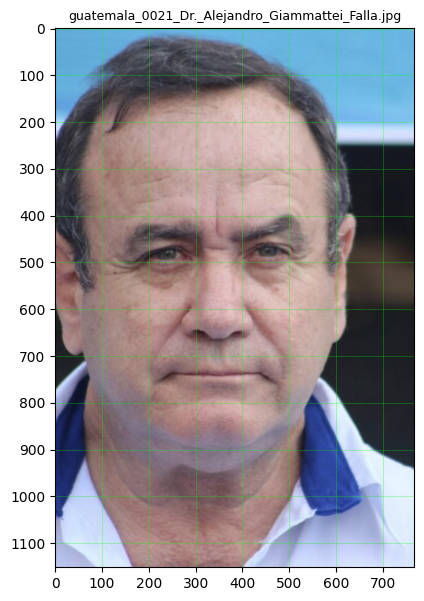

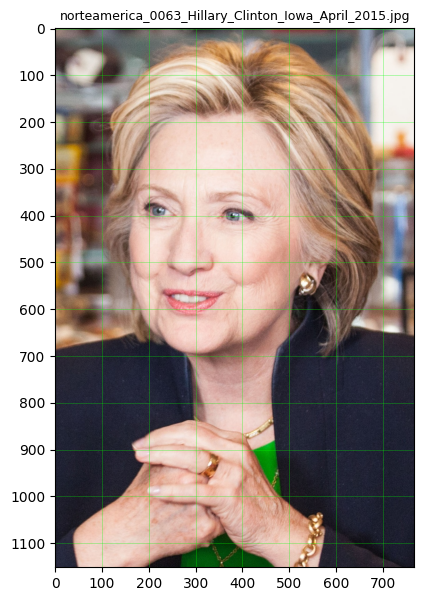

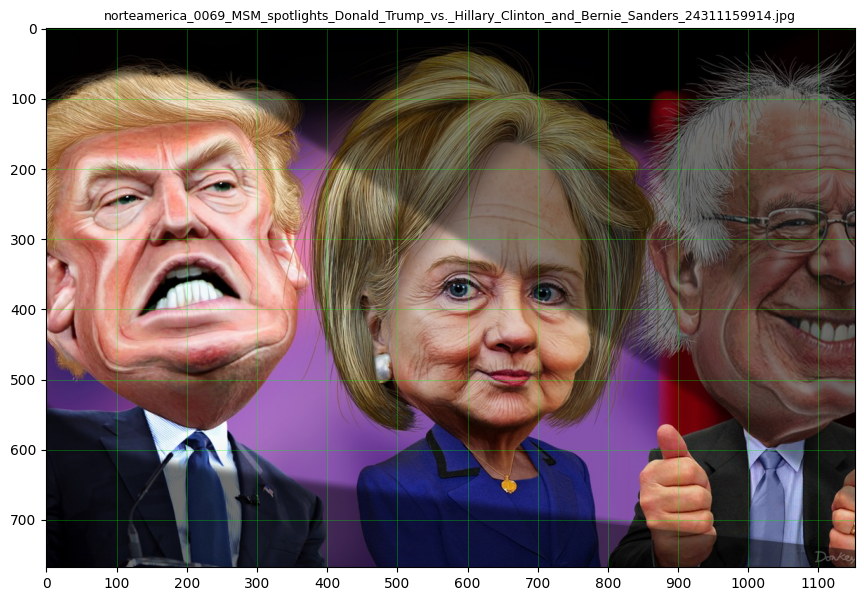

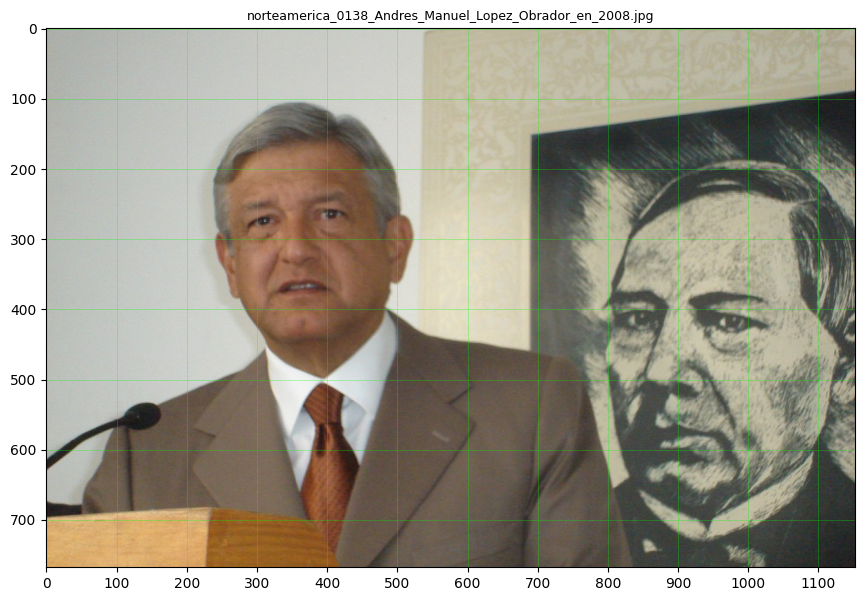

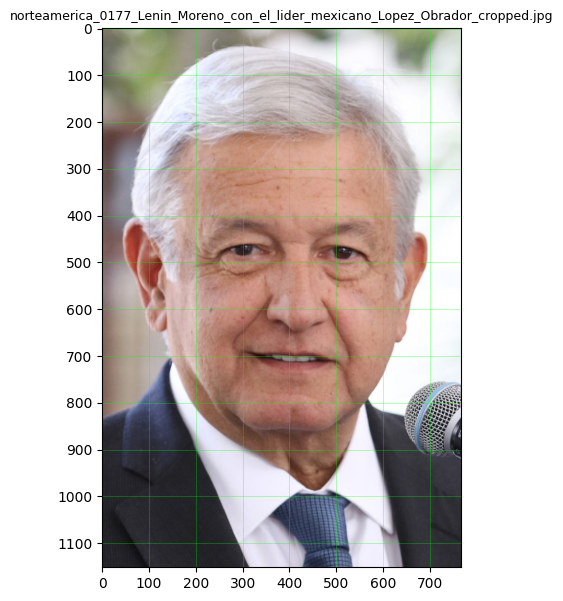

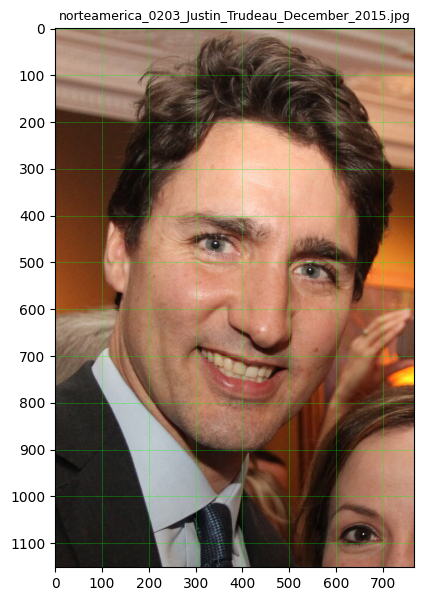

In [ ]:
import matplotlib.pyplot as plt

hechas = {f[:-5] for f in os.listdir(f"{DRIVE}/registros") if f.endswith(".json")}
pendientes = [a for a in REALES if os.path.splitext(a)[0] not in hechas]
print(pendientes)

for archivo in pendientes:
    img = Image.open(f"{LOCAL}/real/{archivo}").convert("RGB")
    fig, ax = plt.subplots(figsize=(11, 7))
    ax.imshow(img); ax.set_title(archivo, fontsize=9)
    ax.set_xticks(range(0, img.size[0], 100)); ax.set_yticks(range(0, img.size[1], 100))
    ax.grid(color="lime", alpha=0.4, linewidth=0.5)
    plt.show()

In [ ]:
filas = []
for f in sorted(os.listdir(f"{DRIVE}/registros")):
    if f.endswith(".json"):
        filas.append(json.load(open(f"{DRIVE}/registros/{f}", encoding="utf-8")))

campos = ["archivo","nivel","tamano","objeto","cambio","evitar","ref","area_img","area_rel",
          "cambio_visible","calidad_jpeg","semilla","modelo_edicion","modelo_vlm","caja","justificacion"]
with open(f"{DRIVE}/catalogo.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=campos, extrasaction="ignore")
    w.writeheader()
    for r in filas:
        r["caja"] = " ".join(map(str, r["caja"]))
        w.writerow(r)

from collections import Counter
print("total:", len(filas))
print("por nivel:", Counter(r["nivel"] for r in filas))
print("por referencia:", Counter(r["ref"] for r in filas))
if os.path.exists(f"{DRIVE}/descartadas.csv"):
    print("descartadas:", sum(1 for _ in open(f"{DRIVE}/descartadas.csv")))

total: 494
por nivel: Counter({'sutil': 176, 'normal': 167, 'obvio': 151})
por referencia: Counter({'escena': 352, 'persona': 142})
descartadas: 816


In [ ]:
import pandas as pd
cat = pd.read_csv(f"{DRIVE}/catalogo.csv")
for ref in ("persona", "escena"):
    sub = cat[cat.ref == ref]
    print(f"\n--- {ref} (n={len(sub)}) ---")
    print(sub.groupby("nivel")["area_rel"].describe()[["count","min","25%","50%","75%","max"]].round(2))
    print(sub.groupby("nivel")["cambio_visible"].describe()[["min","50%","max"]].round(2))


--- persona (n=142) ---
        count    min    25%    50%    75%    max
nivel                                           
normal   39.0   8.51  12.29  16.23  26.64  38.18
obvio    45.0  42.87  56.90  68.81  78.00  97.64
sutil    58.0   0.24   0.92   1.55   2.79   6.97
         min   50%    max
nivel                    
normal  0.41  1.17   1.97
obvio   3.10  6.00  17.34
sutil   0.02  0.15   0.40

--- escena (n=352) ---
        count   min   25%    50%    75%    max
nivel                                         
normal  128.0  0.84  1.24   1.57   2.21   2.97
obvio   106.0  4.61  7.69  11.26  18.24  58.54
sutil   118.0  0.14  0.34   0.46   0.56   0.80
         min   50%    max
nivel                    
normal  0.41  0.75   2.00
obvio   3.03  6.97  19.66
sutil   0.04  0.16   0.39


In [ ]:
import pandas as pd, os, collections
fallos = pd.read_csv(f"{DRIVE}/descartadas.csv", names=["archivo", "motivo"])
hechas = {f[:-5] + ".jpg" for f in os.listdir(f"{DRIVE}/registros") if f.endswith(".json")}
pend = fallos[~fallos.archivo.isin(hechas)]
ultimos = pend.groupby("archivo").last()["motivo"]

CLAVES = ["no se detectaron personas", "cayó en el entorno", "OWLv2 no encontró",
          "fuera de bandas", "cara o mano", "fuera de banda", "demasiado pequeña",
          "Qwen no cumplió", "sin candidatos", "ninguna generación"]

def motivo(m):
    for c in CLAVES:
        if c in m: return c
    return m[-60:]

print("imágenes sin pareja:", len(ultimos))
print(collections.Counter(motivo(m) for m in ultimos).most_common())

imágenes sin pareja: 6
[('ninguna generación', 4), ('sertionError: ningún objeto del vocabulario quedó utilizable', 2)]


In [ ]:
import pandas as pd
cat = pd.read_csv(f"{DRIVE}/catalogo.csv")
for ref in ("persona", "escena"):
    sub = cat[cat.ref == ref]
    print(f"\n--- {ref} (n={len(sub)}) ---")
    print(sub.groupby("nivel")["area_rel"].describe()[["count","min","25%","50%","75%","max"]].round(2))
    print(sub.groupby("nivel")["cambio_visible"].describe()[["min","50%","max"]].round(2))


--- persona (n=142) ---
        count    min    25%    50%    75%    max
nivel                                           
normal   39.0   8.51  12.29  16.23  26.64  38.18
obvio    45.0  42.87  56.90  68.81  78.00  97.64
sutil    58.0   0.24   0.92   1.55   2.79   6.97
         min   50%    max
nivel                    
normal  0.41  1.17   1.97
obvio   3.10  6.00  17.34
sutil   0.02  0.15   0.40

--- escena (n=352) ---
        count   min   25%    50%    75%    max
nivel                                         
normal  128.0  0.84  1.24   1.57   2.21   2.97
obvio   106.0  4.61  7.69  11.26  18.24  58.54
sutil   118.0  0.14  0.34   0.46   0.56   0.80
         min   50%    max
nivel                    
normal  0.41  0.75   2.00
obvio   3.03  6.97  19.66
sutil   0.04  0.16   0.39


## Auditoría de las dos clases

In [ ]:
import pandas as pd, os
from PIL import Image

cat = pd.read_csv(f"{DRIVE}/catalogo.csv")
filas = []
for archivo in cat["archivo"]:
    for clase, ruta in (("real", f"{LOCAL}/real/{archivo}"),
                        ("manipulada", f"{DRIVE}/manipuladas/{archivo}")):
        im = Image.open(ruta)
        filas.append(dict(clase=clase, archivo=archivo, ancho=im.size[0], alto=im.size[1],
                          modo=im.mode, formato=im.format,
                          kb=os.path.getsize(ruta)/1024))
aud = pd.DataFrame(filas)

print(aud.groupby("clase")[["ancho","alto","kb"]].describe().round(1).T)
print("\nmodos:", aud.groupby("clase")["modo"].value_counts().to_dict())
print("formatos:", aud.groupby("clase")["formato"].value_counts().to_dict())
print("\npares incompletos:", aud.groupby("archivo").size().ne(2).sum())
aud.to_csv(f"{DRIVE}/auditoria_clases.csv", index=False)

clase        manipulada    real
ancho count       494.0   494.0
      mean       1076.6  1076.6
      std         152.7   152.7
      min         768.0   768.0
      25%        1152.0  1152.0
      50%        1152.0  1152.0
      75%        1152.0  1152.0
      max        1152.0  1152.0
alto  count       494.0   494.0
      mean        843.4   843.4
      std         152.7   152.7
      min         768.0   768.0
      25%         768.0   768.0
      50%         768.0   768.0
      75%         768.0   768.0
      max        1152.0  1152.0
kb    count       494.0   494.0
      mean        248.6   251.3
      std         138.2   141.2
      min          61.8    61.0
      25%         137.3   138.1
      50%         209.1   210.3
      75%         337.9   339.4
      max         693.0   699.4

modos: {('manipulada', 'RGB'): 494, ('real', 'RGB'): 494}
formatos: {('manipulada', 'JPEG'): 494, ('real', 'JPEG'): 494}

pares incompletos: 0


#Partición por parejas

In [ ]:
import numpy as np
rng = np.random.default_rng(22500)

cat = pd.read_csv(f"{DRIVE}/catalogo.csv").sample(frac=1, random_state=22500)
cat["particion"] = ""
N_ESTRES = 100

for nivel, grupo in cat.groupby("nivel"):
    idx = grupo.index.to_numpy()
    n_estres = round(N_ESTRES * len(idx) / len(cat))
    estres, resto = idx[:n_estres], idx[n_estres:]
    n_tr = int(0.70 * len(resto)); n_va = int(0.15 * len(resto))
    cat.loc[estres, "particion"] = "estres"
    cat.loc[resto[:n_tr], "particion"] = "entrenamiento"
    cat.loc[resto[n_tr:n_tr+n_va], "particion"] = "validacion"
    cat.loc[resto[n_tr+n_va:], "particion"] = "prueba"

print(pd.crosstab(cat.particion, cat.nivel, margins=True))
cat.to_csv(f"{DRIVE}/catalogo.csv", index=False)
print("\nparticiones guardadas en catalogo.csv")

nivel          normal  obvio  sutil  All
particion                               
entrenamiento      93     84     98  275
estres             34     31     36  101
prueba             21     18     21   60
validacion         19     18     21   58
All               167    151    176  494

particiones guardadas en catalogo.csv
